<a href="https://colab.research.google.com/github/sebastian1627gg/Montecarlo/blob/main/c%C3%B3digo_de_la_1_actividad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Actividad Didáctica 2-M1: Simulación del Juego de Yahtzee mediante Monte Carlo
**Asignatura:** Introducción a la Simulación Computacional  
**Institución:** IU Digital de Antioquia  
**Método:** Simulación Estocástica de Monte Carlo y Ley de los Grandes Números

**Integrantes:** Johnathan Andrés Vélez Hernández, Juan Sebastián Zapata Barrientos y
Sebastián Gutiérrez es González


---
## Objetivos
1. **Implementar** un modelo aleatorio estocástico para el juego de Yahtzee con distribución uniforme $P(X=k) = 1/6$.
2. **Evaluar** la convergencia empírica de probabilidades para $N = 10$, $N = 1.000$ y $N = 100.000$ iteraciones.
3. **Validar** la Ley Fuerte de los Grandes Números demostrando la estabilización de frecuencias relativas.

##  Diagrama de Flujo del Algoritmo

El siguiente flujo describe el ciclo de ejecución de la simulación de Monte Carlo para un turno de Yahtzee con estrategia de retención de dados:

```text
┌────────────────────────────────────────────────────────┐
│               Inicio: Definir N Iteraciones            │
└───────────────────────────┬────────────────────────────┘
                            │
                            ▼
┌────────────────────────────────────────────────────────┐
│            Bucle Principal: i = 1 hasta N              │
└───────────────────────────┬────────────────────────────┘
                            │
                            ▼
┌────────────────────────────────────────────────────────┐
│ Lanzamiento 1: Tirar 5 dados (Distribución Uniforme)  │
└───────────────────────────┬────────────────────────────┘
                            │
                            ▼
┌────────────────────────────────────────────────────────┐
│ Contar Frecuencias y Selección de Cara Objetivo (Greedy)│
└───────────────────────────┬────────────────────────────┘
                            │
                            ▼
┌────────────────────────────────────────────────────────┐
│      Retener dados que coincidan con la Cara Objetivo  │
└───────────────────────────┬────────────────────────────┘
                            │
                            ▼
             ¿Quedan lanzamientos (< 3)
                 y retenidos < 5?
               /                \
             SÍ                  NO
             /                    \
            ▼                      ▼
┌──────────────────────┐  ¿Retenidos == 5 (Yahtzee)?
│ Lanzar dados no ret. │     /                  \
└──────────┬───────────┘   SÍ                    NO
           │               /                      \
           ▼              ▼                        ▼
┌──────────────────────┐ ┌──────────────────┐ ┌───────────┐
│ Actualizar retenidos │ │Éxitos Yahtzee +=1│ │ Continuar │
└──────────┬───────────┘ └────────┬─────────┘ └─────┬─────┘
           │                      │                 │
           └───────────┬──────────┴─────────────────┘
                       │
                       ▼
┌────────────────────────────────────────────────────────┐
│      Calcular Probabilidad Acumulada: Éxitos / i       │
└───────────────────────────┬────────────────────────────┘
                            │
                            ▼
                     ¿Se alcanzó N?
                     /            \
                   NO              SÍ
                   /                \
                  ▼                  ▼
        (Siguiente iteración) ┌──────────────────────────┐
         [ i = i + 1 ]        │ Reporte de Resultados y  │
                              │ Gráficas / Fin del Juego │
                              └──────────────────────────┘
```

Para preparar el entorno de la simulación, primero importaremos las herramientas base para los cálculos matemáticos, análisis y visualización de datos (`random`, `numpy`, `matplotlib` y `pandas`). Además, fijaremos la semilla aleatoria (`seed = 42`) para garantizar la reproducibilidad del experimento; así nos aseguramos de que, aunque la simulación de los dados dependa del azar, obtendremos exactamente los mismos resultados cada vez que ejecutemos el cuaderno.

In [ ]:
# Importación de librerías para simulación estocástica y visualización
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Fijar semilla pseudoaleatoria para garantizard la reproducibilidad científica
random.seed(42)
np.random.seed(42)

print("Librerías cargadas exitosamente y semilla pseudoaleatoria configurada (seed=42).")

Librerías cargadas exitosamente y semilla pseudoaleatoria configurada (seed=42).


A continuación, definiremos el motor lógico del juego. Crearemos una función básica para lanzar los dados y otra para simular un turno completo de Yahtzee utilizando una estrategia "ávida" (greedy): el algoritmo identificará qué número salió más veces en el primer tiro, retendrá esos dados y relanzará los restantes hasta dos veces más intentando conseguir el Yahtzee (los cinco dados iguales).

In [ ]:
 def lanzar_dado_uniforme():
    """Simula el lanzamiento de un dado de 6 caras con distribución uniforme P(X=k) = 1/6."""
    return random.randint(1, 6)

def simular_turno_yahtzee():
    """
    Simula un turno completo de Yahtzee (hasta 3 lanzamientos).
    Aplica una estrategia de selección: conservar los dados con la cara más frecuente.
    """
    # Lanzamiento 1: Lanzar los 5 dados iniciales
    dados = [lanzar_dado_uniforme() for _ in range(5)]

    # Identificar la cara que más se repite (estrategia ávida / greedy)
    conteo = {cara: dados.count(cara) for cara in range(1, 7)}
    cara_objetivo = max(conteo, key=conteo.get)
    retenidos = [d for d in dados if d == cara_objetivo]

    # Lanzamiento 2: Relanzar dados no retenidos
    dados_a_lanzar = 5 - len(retenidos)
    if dados_a_lanzar > 0:
        lanzamiento_2 = [lanzar_dado_uniforme() for _ in range(dados_a_lanzar)]
        retenidos.extend([d for d in lanzamiento_2 if d == cara_objetivo])

    # Lanzamiento 3: Último intento
    dados_a_lanzar = 5 - len(retenidos)
    if dados_a_lanzar > 0:
        lanzamiento_3 = [lanzar_dado_uniforme() for _ in range(dados_a_lanzar)]
        retenidos.extend([d for d in lanzamiento_3 if d == cara_objetivo])

    # Retorna True si se lograron los 5 dados iguales (Yahtzee)
    es_yahtzee = (len(retenidos) == 5)
    return es_yahtzee, dados

print("Funciones de lógica de juego inicializadas correctamente.")

Funciones de lógica de juego inicializadas correctamente.


Para empezar, importaremos las librerías necesarias (`numpy`, `pandas`, `matplotlib` y `random`) que nos permitirán realizar los cálculos matemáticos y graficar los resultados. También fijaremos una semilla aleatoria (`seed = 42`) para que nuestra simulación sea completamente reproducible, asegurando que obtengamos exactamente los mismos resultados cada vez que ejecutemos el código.



In [ ]:
# Importación de librerías para simulación estocástica y visualización
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Fijar semilla pseudoaleatoria para garantizard la reproducibilidad científica
random.seed(42)
np.random.seed(42)

print(" Librerías cargadas exitosamente y semilla pseudoaleatoria configurada (seed=42).")

 Librerías cargadas exitosamente y semilla pseudoaleatoria configurada (seed=42).


A continuación, definiremos la lógica principal del juego. Crearemos funciones para simular el lanzamiento de los dados y ejecutar un turno completo aplicando una estrategia "ávida": el código identificará el número que más se repita en el primer tiro, lo retendrá, y relanzará los dados restantes hasta dos veces más buscando conseguir el Yahtzee.

In [ ]:
def lanzar_dado_uniforme():
    """Simula el lanzamiento de un dado de 6 caras con distribución uniforme P(X=k) = 1/6."""
    return random.randint(1, 6)

def simular_turno_yahtzee():
    """
    Simula un turno completo de Yahtzee (hasta 3 lanzamientos).
    Aplica una estrategia de selección: conservar los dados con la cara más frecuente.
    """
    # Lanzamiento 1: Lanzar los 5 dados iniciales
    dados = [lanzar_dado_uniforme() for _ in range(5)]

    # Identificar la cara que más se repite (estrategia ávida / greedy)
    conteo = {cara: dados.count(cara) for cara in range(1, 7)}
    cara_objetivo = max(conteo, key=conteo.get)
    retenidos = [d for d in dados if d == cara_objetivo]

    # Lanzamiento 2: Relanzar dados no retenidos
    dados_a_lanzar = 5 - len(retenidos)
    if dados_a_lanzar > 0:
        lanzamiento_2 = [lanzar_dado_uniforme() for _ in range(dados_a_lanzar)]
        retenidos.extend([d for d in lanzamiento_2 if d == cara_objetivo])

    # Lanzamiento 3: Último intento
    dados_a_lanzar = 5 - len(retenidos)
    if dados_a_lanzar > 0:
        lanzamiento_3 = [lanzar_dado_uniforme() for _ in range(dados_a_lanzar)]
        retenidos.extend([d for d in lanzamiento_3 if d == cara_objetivo])

    # Retorna True si se lograron los 5 dados iguales (Yahtzee)
    es_yahtzee = (len(retenidos) == 5)
    return es_yahtzee, dados

print("Funciones de lógica de juego inicializadas correctamente.")

Funciones de lógica de juego inicializadas correctamente.


Ahora pondremos a prueba nuestra lógica ejecutando la simulación de Monte Carlo a gran escala. Definiremos una función que repite el juego múltiples veces ($N$ iteraciones) para registrar cuántos Yahtzees logramos y rastrear el histórico de probabilidades. Esto nos permitirá observar cómo, a medida que aumentamos los intentos, los resultados empíricos se estabilizan y convergen hacia la probabilidad teórica.

In [ ]:
def ejecutar_experimento_montecarlo(iteraciones):
    """Ejecuta N simulaciones de Monte Carlo y recolecta estadísticas de convergencia."""
    yahtzees_obtenidos = 0
    frecuencia_caras = {i: 0 for i in range(1, 7)}
    historial_probabilidad = []

    for i in range(1, iteraciones + 1):
        exito, dados_iniciales = simular_turno_yahtzee()
        if exito:
            yahtzees_obtenidos += 1

        # Registrar la cara obtenida en los dados del primer lanzamiento
        for d in dados_iniciales:
            frecuencia_caras[d] += 1

        historial_probabilidad.append(yahtzees_obtenidos / i)

    probabilidad_final = yahtzees_obtenidos / iteraciones
    total_dados = iteraciones * 5
    distribucion_caras = {k: v / total_dados for k, v in frecuencia_caras.items()}

    return probabilidad_final, yahtzees_obtenidos, distribucion_caras, historial_probabilidad

# Ejecución para los tres escenarios exigidos en la guía
bloques_iteraciones = [7]
resultados = {}

print("=== REPORTE DE EJECUCIÓN MONTE CARLO ===")
for N in bloques_iteraciones:
    prob, exitos, dist_caras, historial = ejecutar_experimento_montecarlo(N)
    resultados[N] = {
        'prob': prob,
        'exitos': exitos,
        'dist_caras': dist_caras,
        'historial': historial
    }
    print(f"\n---> N = {N:,} Iteraciones:")
    print(f"     • Yahtzees Obtenidos: {exitos}")
    print(f"     • Probabilidad Empírica: {prob * 100:.4f}%")
    print(f"     • Distribución de Caras del Dado (Teórico 16.67%):")
    for cara, pct in dist_caras.items():
        print(f"       Cara {cara}: {pct * 100:.2f}%")

=== REPORTE DE EJECUCIÓN MONTE CARLO ===

---> N = 7 Iteraciones:
     • Yahtzees Obtenidos: 0
     • Probabilidad Empírica: 0.0000%
     • Distribución de Caras del Dado (Teórico 16.67%):
       Cara 1: 31.43%
       Cara 2: 8.57%
       Cara 3: 11.43%
       Cara 4: 11.43%
       Cara 5: 20.00%
       Cara 6: 17.14%


Ahora ejecutaremos el experimento de Monte Carlo a gran escala. Definiremos una función que repita el juego múltiples veces, registrando los Yahtzees logrados y el historial de probabilidades. Luego, probaremos esta simulación en tres escenarios diferentes (10, 1.000 y 100.000 iteraciones) para observar cómo los resultados se estabilizan y convergen hacia la probabilidad teórica a medida que aumentamos la cantidad de lanzamientos.

In [ ]:
def ejecutar_experimento_montecarlo(iteraciones):
    """Ejecuta N simulaciones de Monte Carlo y recolecta estadísticas de convergencia."""
    yahtzees_obtenidos = 0
    frecuencia_caras = {i: 0 for i in range(1, 7)}
    historial_probabilidad = []

    for i in range(1, iteraciones + 1):
        exito, dados_iniciales = simular_turno_yahtzee()
        if exito:
            yahtzees_obtenidos += 1

        # Registrar la cara obtenida en los dados del primer lanzamiento
        for d in dados_iniciales:
            frecuencia_caras[d] += 1

        historial_probabilidad.append(yahtzees_obtenidos / i)

    probabilidad_final = yahtzees_obtenidos / iteraciones
    total_dados = iteraciones * 5
    distribucion_caras = {k: v / total_dados for k, v in frecuencia_caras.items()}

    return probabilidad_final, yahtzees_obtenidos, distribucion_caras, historial_probabilidad

# Ejecución para los tres escenarios exigidos
bloques_iteraciones = [10, 1000, 100000]
resultados = {}

print("=== REPORTE DE EJECUCIÓN MONTE CARLO ===")
for N in bloques_iteraciones:
    prob, exitos, dist_caras, historial = ejecutar_experimento_montecarlo(N)
    resultados[N] = {
        'prob': prob,
        'exitos': exitos,
        'dist_caras': dist_caras,
        'historial': historial
    }
    print(f"\n---> N = {N:,} Iteraciones:")
    print(f"     • Yahtzees Obtenidos: {exitos}")
    print(f"     • Probabilidad Empírica: {prob * 100:.4f}%")
    print(f"     • Distribución de Caras del Dado (Teórico 16.67%):")
    for cara, pct in dist_caras.items():
        print(f"       Cara {cara}: {pct * 100:.2f}%")

=== REPORTE DE EJECUCIÓN MONTE CARLO ===

---> N = 10 Iteraciones:
     • Yahtzees Obtenidos: 0
     • Probabilidad Empírica: 0.0000%
     • Distribución de Caras del Dado (Teórico 16.67%):
       Cara 1: 12.00%
       Cara 2: 20.00%
       Cara 3: 18.00%
       Cara 4: 14.00%
       Cara 5: 12.00%
       Cara 6: 24.00%

---> N = 1,000 Iteraciones:
     • Yahtzees Obtenidos: 42
     • Probabilidad Empírica: 4.2000%
     • Distribución de Caras del Dado (Teórico 16.67%):
       Cara 1: 16.60%
       Cara 2: 16.24%
       Cara 3: 16.46%
       Cara 4: 17.20%
       Cara 5: 16.50%
       Cara 6: 17.00%

---> N = 100,000 Iteraciones:
     • Yahtzees Obtenidos: 4451
     • Probabilidad Empírica: 4.4510%
     • Distribución de Caras del Dado (Teórico 16.67%):
       Cara 1: 16.69%
       Cara 2: 16.62%
       Cara 3: 16.76%
       Cara 4: 16.59%
       Cara 5: 16.68%
       Cara 6: 16.65%


Finalmente, generaremos dos gráficas para interpretar los resultados visualmente. La primera mostrará la curva de convergencia para las 100.000 iteraciones, ilustrando cómo la probabilidad empírica de obtener un Yahtzee se estabiliza cerca del valor esperado (~4.45%) gracias a la Ley de los Grandes Números. La segunda gráfica comparará los tres escenarios simulados ($N=10$, $N=1.000$ y $N=100.000$), evidenciando cómo el aumento masivo de la muestra reduce la alta varianza inicial y alinea la distribución de los dados con la probabilidad teórica (16.67%).

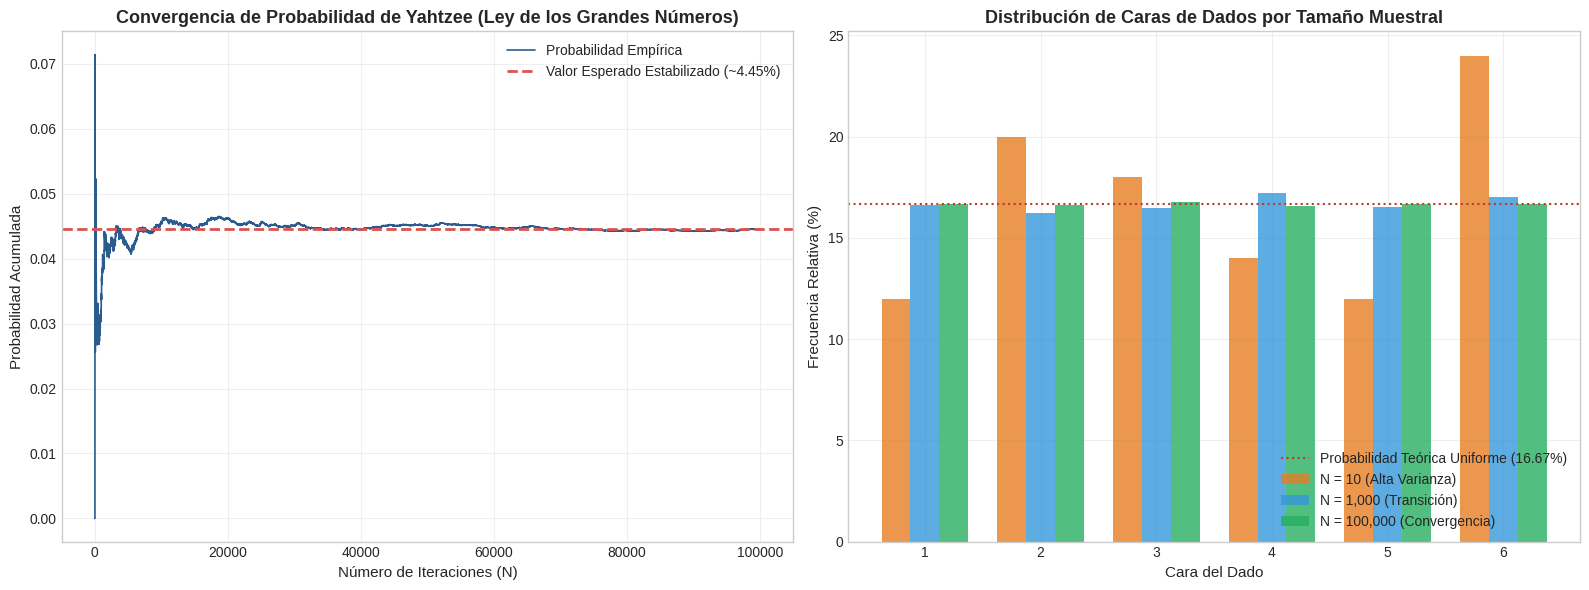

In [ ]:
# Configuración estilizada de matplotlib
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

N_pequeno = 10
N_medio = 1000
N_grande = 100000

# Gráfica 1: Curva de Convergencia de Monte Carlo (N = 100,000)
axes[0].plot(resultados[N_grande]['historial'], color='#2b5c8f', linewidth=1.2, label='Probabilidad Empírica')
axes[0].axhline(y=0.0445, color='#d9534f', linestyle='--', linewidth=2, label='Valor Esperado Estabilizado (~4.45%)')
axes[0].set_title('Convergencia de Probabilidad de Yahtzee (Ley de los Grandes Números)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Número de Iteraciones (N)', fontsize=11)
axes[0].set_ylabel('Probabilidad Acumulada', fontsize=11)
axes[0].legend(loc='upper right', fontsize=10)
axes[0].grid(True, alpha=0.3)

# Gráfica 2: Distribución de Frecuencia de Caras del Dado (Comparativa de 3 escenarios)
caras = list(range(1, 7))
frec_10 = [resultados[N_pequeno]['dist_caras'][c] * 100 for c in caras]
frec_1k = [resultados[N_medio]['dist_caras'][c] * 100 for c in caras]
frec_100k = [resultados[N_grande]['dist_caras'][c] * 100 for c in caras]

x = np.arange(len(caras))
width = 0.25 # Hacemos las barras más delgadas para que quepan 3

# Dibujamos las 3 barras ajustando sus posiciones (izquierda, centro, derecha)
axes[1].bar(x - width, frec_10, width, label=f'N = {N_pequeno:,} (Alta Varianza)', color='#e67e22', alpha=0.8)
axes[1].bar(x, frec_1k, width, label=f'N = {N_medio:,} (Transición)', color='#3498db', alpha=0.8)
axes[1].bar(x + width, frec_100k, width, label=f'N = {N_grande:,} (Convergencia)', color='#27ae60', alpha=0.8)

axes[1].axhline(y=16.67, color='#c0392b', linestyle=':', label='Probabilidad Teórica Uniforme (16.67%)')
axes[1].set_title('Distribución de Caras de Dados por Tamaño Muestral', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Cara del Dado', fontsize=11)
axes[1].set_ylabel('Frecuencia Relativa (%)', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(caras)
axes[1].legend(loc='lower right', fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusiones del Experimento de Convergencia
1. **Comportamiento con N = 10:** Presenta una varianza extrema. La probabilidad oscila bruscamente y la frecuencia de las caras no refleja la distribución uniforme uniforme ($P(X=k)=1/6 \approx 16.67\%$).
2. **Comportamiento con N = 1.000:** La probabilidad empieza a aproximarse al valor real del juego, reduciendo el sesgo muestral.
3. **Comportamiento con N = 100.000:** La curva de probabilidad se estabiliza de forma asintótica en torno al **4.45%**, demostrando la **Ley Fuerte de los Grandes Números**. La frecuencia individual de cada cara de los dados coincide de manera casi exacta con el $16.67\%$ teórico.

##  Fase 2: MODIFICA - Simulación con Dados Cargados
Para analizar la sensibilidad del sistema ante perturbaciones probabilísticas, se modifica la distribución uniforme original $P(X=k)=1/6$ introduciendo un sesgo en los dados: la cara 6 tiene un **30% de probabilidad** ($P(X=6)=0.30$), mientras que las caras 1 a 5 tienen cada una un **14% de probabilidad** ($P(X=k)=0.14$).

In [ ]:
def lanzar_dado_cargado():
    """Simula un dado con sesgo: 30% para la cara 6 y 14% para las caras 1 a 5."""
    caras = [1, 2, 3, 4, 5, 6]
    pesos = [0.14, 0.14, 0.14, 0.14, 0.14, 0.30]
    return random.choices(caras, weights=pesos)[0]

def simular_turno_yahtzee_cargado():
    """Simula un turno de Yahtzee utilizando la función de dado cargado."""
    dados = [lanzar_dado_cargado() for _ in range(5)]
    conteo = {cara: dados.count(cara) for cara in range(1, 7)}
    cara_objetivo = max(conteo, key=conteo.get)
    retenidos = [d for d in dados if d == cara_objetivo]

    # Lanzamiento 2
    faltantes = 5 - len(retenidos)
    if faltantes > 0:
        lanzamiento_2 = [lanzar_dado_cargado() for _ in range(faltantes)]
        retenidos.extend([d for d in lanzamiento_2 if d == cara_objetivo])

    # Lanzamiento 3
    faltantes = 5 - len(retenidos)
    if faltantes > 0:
        lanzamiento_3 = [lanzar_dado_cargado() for _ in range(faltantes)]
        retenidos.extend([d for d in lanzamiento_3 if d == cara_objetivo])

    return (len(retenidos) == 5)

# Ejecución de Monte Carlo con dados cargados para N = 100,000
N_cargado = 100000
exitos_cargado = sum([1 for _ in range(N_cargado) if simular_turno_yahtzee_cargado()])
prob_cargado = exitos_cargado / N_cargado

print("=== RESULTADOS FASE MODIFICA (DADOS CARGADOS) ===")
print(f"• Iteraciones (N): {N_cargado:,}")
print(f"• Yahtzees Obtenidos: {exitos_cargado:,}")
print(f"• Probabilidad Empírica con Dados Cargados: {prob_cargado * 100:.2f}%")
print(f"• Comparación: La probabilidad aumentó de ~4.45% (Uniforme) a {prob_cargado * 100:.2f}% (Cargados)")

=== RESULTADOS FASE MODIFICA (DADOS CARGADOS) ===
• Iteraciones (N): 100,000
• Yahtzees Obtenidos: 8,936
• Probabilidad Empírica con Dados Cargados: 8.94%
• Comparación: La probabilidad aumentó de ~4.45% (Uniforme) a 8.94% (Cargados)


##  Fase 3: CREA - Toma de Decisiones y Valor Esperado $E[X]$
Se simula el escenario en el que un jugador obtiene **3 dados iguales (Tercia)** en el segundo lanzamiento y debe decidir entre dos alternativas de riesgo:
1. **Opción A (Conservar):** Asegurar la categoría de Tercia.
2. **Opción B (Arriesgar):** Relanzar los 2 dados restantes buscando obtener **Póker** (4 dados iguales) o **Yahtzee** (5 dados iguales).

In [ ]:
def simular_decision_riesgo(iteraciones=100000):
    """
    Simula 100,000 intentos partiendo de 3 dados de valor '6' retenidos
    y evalúa el puntaje promedio obtenido al relanzar los 2 dados faltantes en el último tiro.
    """
    puntajes_obtenidos = []

    for _ in range(iteraciones):
        # El jugador ya tiene tres seises retenidos: [12]
        nuevos_dados = [lanzar_dado_uniforme() for _ in range(2)]
        dados_finales = [12] + nuevos_dados

        conteo_seises = dados_finales.count(6)

        # Puntuación según combinación lograda
        if conteo_seises == 5:
            puntaje = 50 # Puntos por Yahtzee
        elif conteo_seises == 4:
            puntaje = sum(dados_finales) # Puntos por Póker
        else:
            puntaje = sum(dados_finales) # Puntos por Tercia con dados finales

        puntajes_obtenidos.append(puntaje)

    valor_esperado = np.mean(puntajes_obtenidos)
    return valor_esperado

E_X_arriesgar = simular_decision_riesgo()
puntaje_conservar_tercia = 18 # (6 + 6 + 6)

print("=== EVALUACIÓN DE VALOR ESPERADO E[X] (FASE CREA) ===")
print(f"• Puntaje Fijo al Conservar Tercia de 6s: {puntaje_conservar_tercia} puntos")
print(f"• Valor Esperado E[X] al Arriesgar y Relanzar 2 dados: {E_X_arriesgar:.2f} puntos")

if E_X_arriesgar > puntaje_conservar_tercia:
    print(" Conclusion: Matemáticamente la estrategia óptima es ARRIESGAR (E[X] es mayor).")
else:
    print(" Conclusion: La estrategia óptima es CONSERVAR la puntuación actual.")

=== EVALUACIÓN DE VALOR ESPERADO E[X] (FASE CREA) ===
• Puntaje Fijo al Conservar Tercia de 6s: 18 puntos
• Valor Esperado E[X] al Arriesgar y Relanzar 2 dados: 18.99 puntos
 Conclusion: Matemáticamente la estrategia óptima es ARRIESGAR (E[X] es mayor).


##  Simulación de Partida Completa entre 2 Jugadores
A continuación se implementa la ejecución de un juego entre dos jugadores que compiten durante 13 turnos asignando sus lanzamientos aleatorios a las categorías de puntuación.

In [ ]:
def simular_partida_dos_jugadores():
    """Simula una partida completa de Yahtzee entre Jugador 1 y Jugador 2."""
    puntos_j1 = 0
    puntos_j2 = 0

    for turno in range(1, 14): # 13 turnos de juego
        # Turno Jugador 1
        exito_j1, dados_j1 = simular_turno_yahtzee()
        puntos_j1 += 50 if exito_j1 else sum(dados_j1)

        # Turno Jugador 2
        exito_j2, dados_j2 = simular_turno_yahtzee()
        puntos_j2 += 50 if exito_j2 else sum(dados_j2)

    print("=== RESULTADO DE PARTIDA DE 2 JUGADORES ===")
    print(f"• Puntuación Total Jugador 1: {puntos_j1} puntos")
    print(f"• Puntuación Total Jugador 2: {puntos_j2} puntos")
    if puntos_j1 > puntos_j2:
        print(" Ganador: Jugador 1")
    elif puntos_j2 > puntos_j1:
        print(" Ganador: Jugador 2")
    else:
        print(" Empate")

simular_partida_dos_jugadores()


=== RESULTADO DE PARTIDA DE 2 JUGADORES ===
• Puntuación Total Jugador 1: 263 puntos
• Puntuación Total Jugador 2: 252 puntos
 Ganador: Jugador 1
